# Part 4 - Drift and Observability Using One UWB Beacon

This notebook demonstrates relative pose estimation with a single UWB anchor, fusing noisy odometry (VIO) with UWB range measurements using an Unscented Particle Filter (UPF), in which each particle runs an Unscented Kalman Filter (UKF). We explore drift propagation and observability analysis in this configuration.

In [1]:
# Cell 2: Imports
import sys
sys.path.insert(0, '../src')
import numpy as np
from config import TrajectoryConfig, VIOConfig, UWBNoiseConfig
from part4_functions import estimate_robot_location_with_beacon, track_robot_location_with_beacon, estimate_anchor_from_robot

duration = 50.0
timestep = 0.1

## Correcting drift with a single UWB anchor
Play around with the parameters below to see how a single UWB anchor can help correct drift in the robot's pose estimation.

What do you observe when comparing to the SLAM?

Do you observe any drift in the robot's pose estimation?

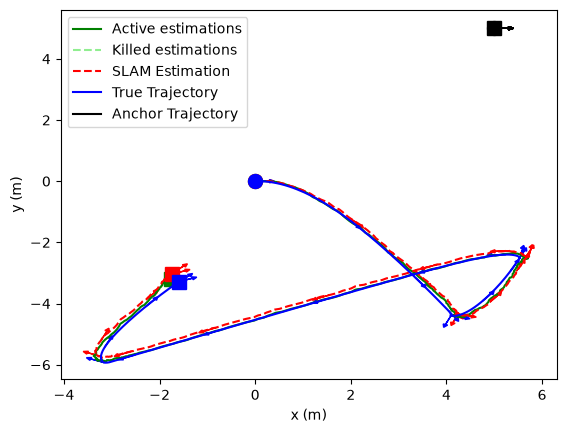

1


In [2]:
anchor_pos = np.array([5.0, 5.0])
sigma_v = 0.1
sigma_w = 0.001
sigma_uwb = 0.1

traj_conf = TrajectoryConfig(duration=duration, timestep=timestep, seed=42)


vio_cfg = VIOConfig(sig_v=sigma_v, sig_w=sigma_w)
uwb_cfg = UWBNoiseConfig(sig_range=sigma_uwb)
track_robot_location_with_beacon(
    traj_conf, vio_cfg, uwb_cfg, anchor_pos,
    n_azimuth=4, n_heading=4, seed=42
)

## Estimating the robot's location with a single UWB anchor
In this section, we will explore how to estimate the robot's location using a single UWB anchor, however we do not know the start pose.

What do you observe now? Does the robot's pose estimation converge?
What does that mean?

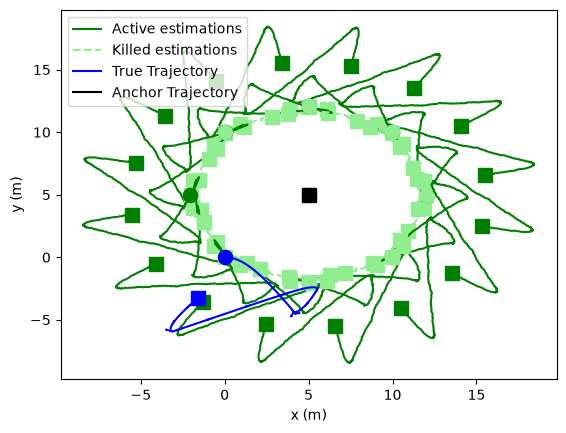

16


In [3]:
anchor_pos = np.array([5.0, 5.0])
sigma_v = 0.1
sigma_w = 0.1
sigma_uwb = 0.1

traj_conf = TrajectoryConfig(duration=duration, timestep=timestep, seed=42)


vio_cfg = VIOConfig(sig_v=sigma_v, sig_w=sigma_w)
uwb_cfg = UWBNoiseConfig(sig_range=sigma_uwb)
estimate_robot_location_with_beacon(
    traj_conf, vio_cfg, uwb_cfg, anchor_pos,
    n_azimuth=8, n_heading=8, seed=42
)

## Estimating the relative location of an anchor
Now we do the inverse, we are not interested in estimating the robot's location, but we want to estimate the anchor's location from the robot's trajectory and UWB measurements.
What happens to the estimations of the anchor's position? Could this be useful?


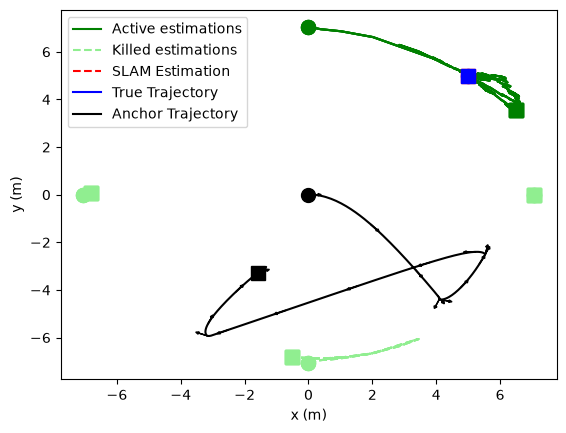

4


In [4]:
anchor_pos = np.array([5.0, 5.0])
sigma_v = 0.1
sigma_w = 0.1
sigma_uwb = 0.1

traj_conf = TrajectoryConfig(duration=duration, timestep=timestep, seed=42)


vio_cfg = VIOConfig(sig_v=sigma_v, sig_w=sigma_w)
uwb_cfg = UWBNoiseConfig(sig_range=sigma_uwb)
estimate_anchor_from_robot(
    traj_conf, vio_cfg, uwb_cfg, anchor_pos,
    n_azimuth=4, n_heading=4, seed=42
)